# Spontaneous-combustion early-warning system — end-to-end notebook
**MI 302 – Mine Hazards, Rescue and Recovery** · NITK Surathkal

Goal: detect the stage of coal self-heating (Normal → Incubation → Active heating → Fire) from gas-sensor streams
*earlier* than fixed gas-ratio thresholds, without more false alarms.

Heavy steps (simulation, model training, full evaluation) are run by `scripts/01…05` and cached; this notebook
re-runs the key steps live and reads the cached results. **All data is simulated — see `docs/ASSUMPTIONS.md`.**

In [1]:
import json, pickle, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
R = json.load(open("../reports/results.json"))
df = pd.read_parquet("../data/processed/sensors.parquet")
print(df.shape, "rows;", df.episode_id.nunique(), "episodes")

(1152000, 19) rows; 600 episodes


## 1. Background: what the gases tell us
* Coal oxidises in air; heat builds up where ventilation is too weak to remove it but oxygen still reaches the coal.
* Oxidation consumes O₂ and releases CO and CO₂. CO grows much faster than O₂ consumption as temperature rises.
* **Oxygen deficiency** = 0.265·N₂ − O₂ · **Graham's ratio** = 100·CO% / O₂ deficiency% · **Young's ratio** = excess CO₂ / O₂ deficiency · **CO make** = CO × airflow.

## 2. Data: a physics-informed simulator
A hidden coal temperature (Semenov heat balance) drives gas generation; shot-firing, diesel, ventilation changes, barometric pumping and sensor faults are added on top.

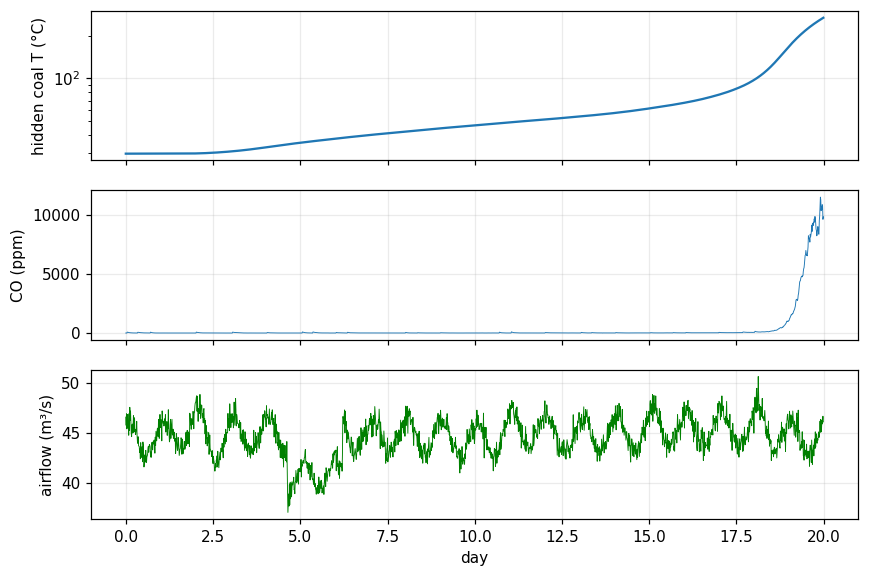

In [2]:
from ews.simulator.episode import sample_spec, simulate_episode
spec = sample_spec("runaway", 11)
sen, lat = simulate_episode(spec)
fig, ax = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
ax[0].plot(sen.t_days, lat.coal_temp_c); ax[0].set_yscale("log"); ax[0].set_ylabel("hidden coal T (°C)")
ax[1].plot(sen.t_days, sen.co_ppm, lw=.6); ax[1].set_ylabel("CO (ppm)")
ax[2].plot(sen.t_days, sen.airflow_m3s, lw=.6, color="g"); ax[2].set_ylabel("airflow (m³/s)"); ax[2].set_xlabel("day")
plt.show()

          benign  fast_runaway  normal  quench  runaway  slow_runaway  \
episodes      90            30     180      60      102            78   

          stable_warm  
episodes           60  
share of rows per stage: {'Normal': 0.748, 'Incubation': 0.175, 'Active Heating': 0.017, 'Fire': 0.06}


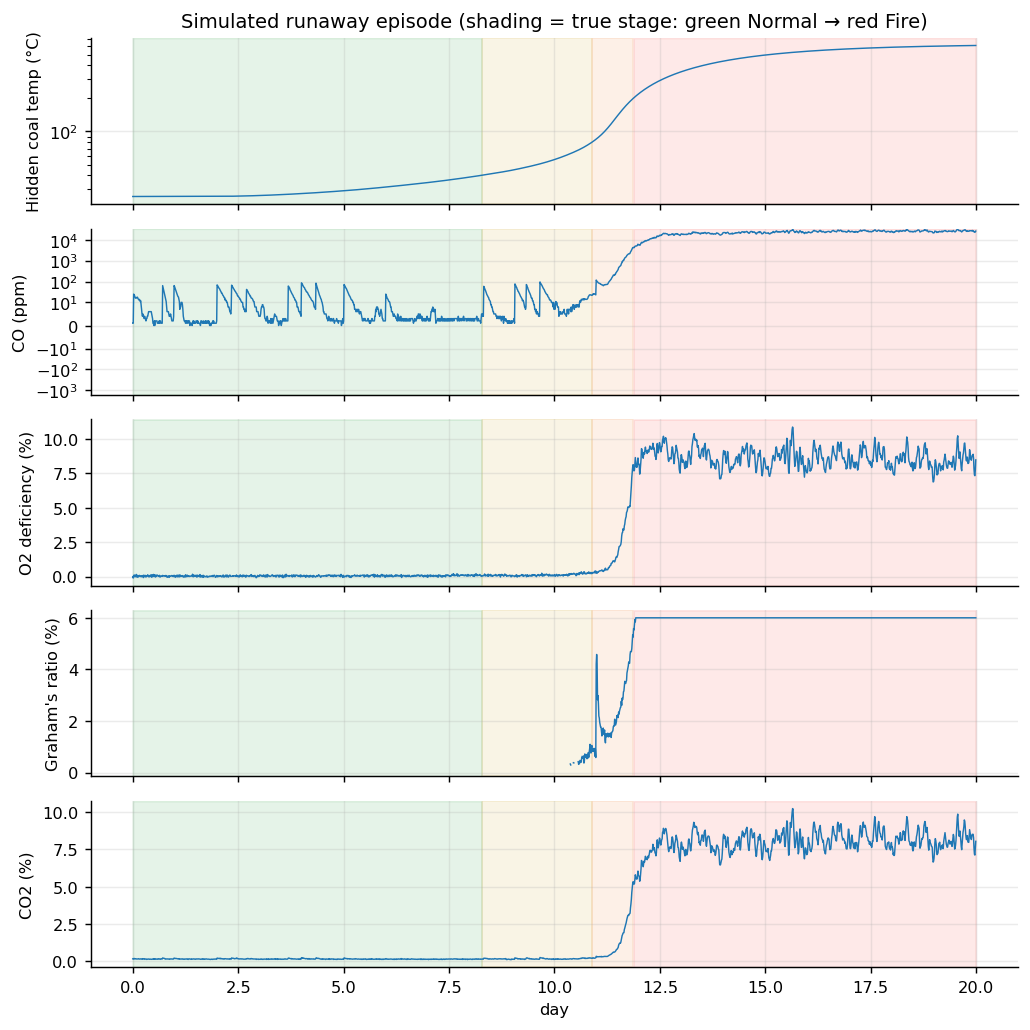

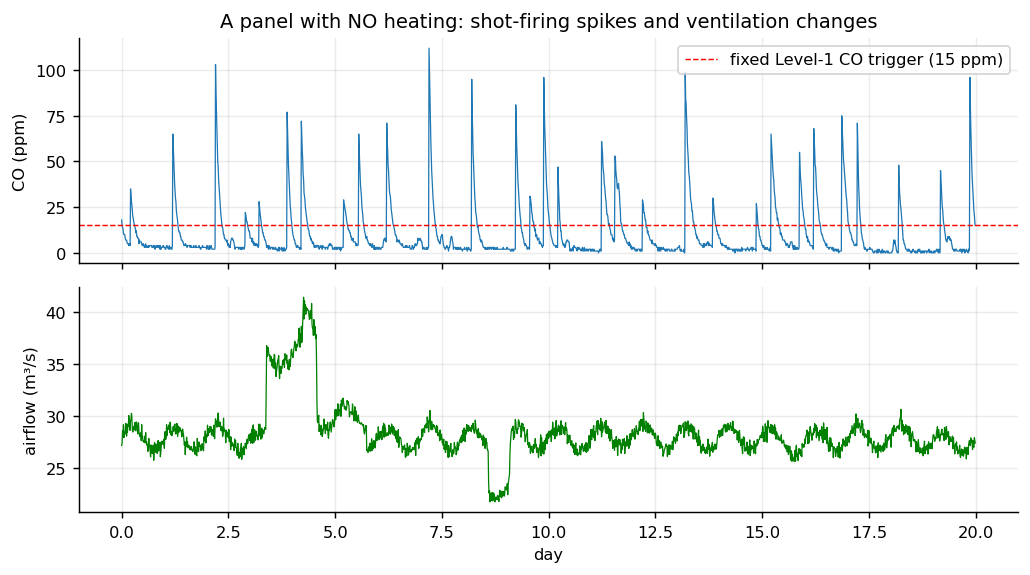

In [3]:
print(pd.DataFrame(R["dataset"]["episodes_by_type"], index=["episodes"]).T.T)
print("share of rows per stage:", {k: round(v, 3) for k, v in R["dataset"]["stage_share_rows"].items()})
display(Image("../reports/figures/fig01_example_episode.png")); display(Image("../reports/figures/fig02_confounders.png"))

## 3. Features
55 *causal* rolling-window features per time step: oxygen deficiency, Graham / Young / CO-CO₂ ratios, CO make, 1–24 h means, medians, minima ("floor"), slopes, ventilation and pressure context, missing-data share.
Medians and minima ignore 1–3 h blasting spikes but still rise during real heating.

In [4]:
from ews.features import build_features, FEATURE_NAMES
F = build_features(sen)
print(len(FEATURE_NAMES), "features, e.g.:", FEATURE_NAMES[:12])
F[["co_ppm","co_med_4h","co_min_24h","co_above_floor","graham_12h_med"]].iloc[::96].round(2).head(12)

55 features, e.g.: ['co_ppm', 'co2_pct', 'o2_pct', 'ch4_pct', 'temp_c', 'airflow', 'o2_def', 'co_make', 'co_mean_1h', 'make_mean_1h', 'co_mean_4h', 'make_mean_4h']


,co_ppm,co_med_4h,co_min_24h,co_above_floor,graham_12h_med
0,2.0,NaN,NaN,NaN,NaN
96,5.0,4.0,1.0,3.0,NaN
192,2.0,2.0,1.0,1.0,0.24
288,2.0,3.0,0.0,3.0,NaN
384,2.0,3.0,0.0,3.0,0.31
480,3.0,3.0,2.0,1.0,0.32
576,4.0,4.0,1.0,3.0,0.63
672,5.0,3.5,1.0,2.5,0.48
768,7.0,4.0,1.0,3.0,0.25
864,3.0,4.5,0.0,4.5,0.33


## 4. Models and stage classification (unseen test panels)

In [5]:
rows = []
for n, v in R["stage"].items():
    rows.append({"model": n, "macro-F1": v["macro_f1"], "quad. kappa": v["qw_kappa"], "mean |stage error|": v["mean_abs_stage_error"],
                 **{f"recall {s}": v["per_class"][s]["recall"] for s in v["per_class"]}})
pd.DataFrame(rows).set_index("model").round(3)

,macro-F1,quad. kappa,mean |stage error|,recall Normal,recall Incubation,recall Active Heating,recall Fire
model,,,,,,,
logreg,0.779,0.806,0.254,0.744,0.657,0.936,0.995
rf,0.820,0.862,0.177,0.871,0.561,0.954,0.994
xgb,0.835,0.879,0.153,0.920,0.495,0.925,0.997
cnn,0.826,0.876,0.157,0.916,0.500,0.905,0.988
lstm,0.814,0.876,0.158,0.915,0.501,0.879,0.985
Manual 8-hourly sampling,0.569,0.732,0.314,0.821,0.194,0.483,0.999
Continuous fixed threshold,0.564,0.718,0.314,0.833,0.180,0.480,0.965


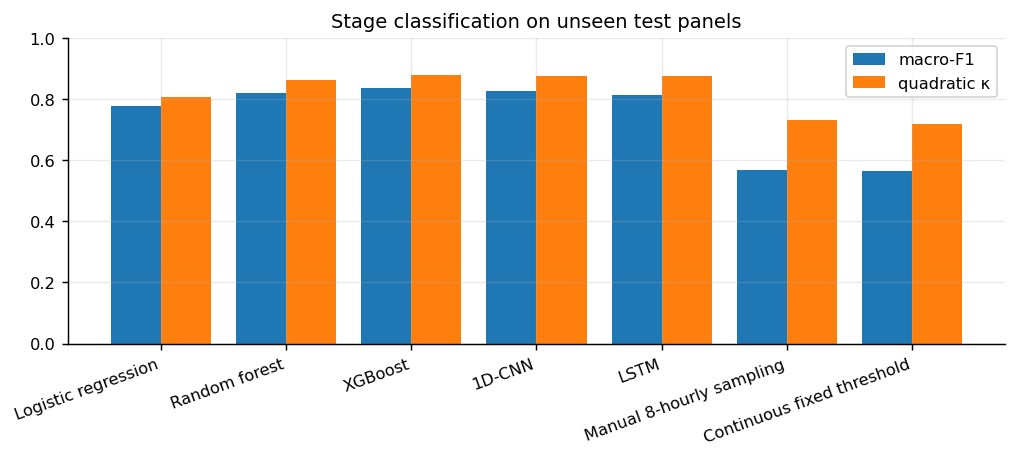

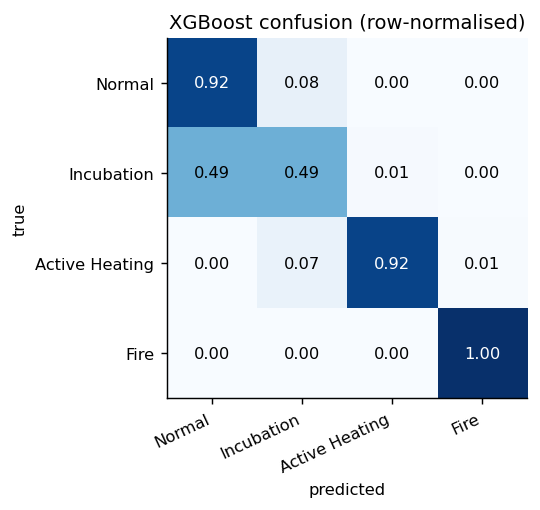

In [6]:
display(Image("../reports/figures/fig03_stage_models.png")); display(Image("../reports/figures/fig04_confusion_xgb.png"))

## 5. The metric that matters: lead time at a matched false-alarm rate
Stage accuracy is not the goal — *warning earlier* is. For each alert level k (stage ≥ k) an alarm fires when P(stage ≥ k) stays above a threshold for m consecutive samples. We pick threshold and m on the **validation** panels so that false alarms ≤ 1 per 100 panel-days, then measure delay on the **test** panels. Every method (including the tuned threshold rule) gets the same budget.

In [7]:
from ews.experiment import make_split, load_probs, calibrate_and_evaluate, summarize
import pandas as pd
F_all = pd.read_parquet("../data/processed/features.parquet")
V, T = make_split(df, F_all, "val"), make_split(df, F_all, "test")
for s in (V, T): s.P["xgb"] = load_probs("xgb", s.name, root=__import__("pathlib").Path("../reports/cache"))
live = calibrate_and_evaluate({"kind": "model", "name": "xgb"}, V, T, 1.0, levels=(2,))
print("LIVE: XGBoost level-2 alert ->", {k: round(v, 2) for k, v in summarize(live[2]).items()})

LIVE: XGBoost level-2 alert -> {'detection_rate': 1.0, 'median_delay_h': -4.5, 'expected_delay_h': -3.09, 'fa_per_100d': 1.7, 'n_events': 39.0, 'false_alarms': 46.0, 'days': 2700.0, 'threshold': 0.1, 'persistence': 2.0, 'val_fa_per_100d': 0.86}


In [8]:
ev = R["events"]; rows = []
for name, per in ev.items():
    for k in ("1", "2", "3"):
        r = per[k]; rows.append({"method": name, "level": k, "detection rate": r["detection_rate"], "median delay (h)": r["median_delay_h"],
                                 "false alarms /100 d": r["fa_per_100d"], "events": r["n_events"]})
tab = pd.DataFrame(rows); tab.pivot(index="method", columns="level", values=["median delay (h)", "false alarms /100 d", "detection rate"]).round(2)

median delay (h)              false alarms /100 d  \
level                                     1      2     3                   1   
method                                                                         
Continuous fixed threshold             1.50   3.62 -6.00               70.33   
Manual 8-hourly sampling               6.00   6.50 -5.38               28.74   
Tuned threshold rule                 121.75  14.38 -6.00                0.96   
cnn                                   80.50  -4.00 -3.00                1.33   
logreg                                89.50  -0.50 -0.50                0.33   
lstm                                  84.75  -0.75 -0.88                0.74   
rf                                    65.12  -3.00 -0.75                2.15   
xgb                                   68.12  -4.50 -0.50                2.00   

                                        detection rate             
level                           2     3              1     2    3  
method                                                             
Continuous fixed threshold  59.30  1.85           1.00  0.97  1.0  
Manual 8-hourly sampling     8.67  0.59           0.93  0.95  1.0  
Tuned threshold rule         0.33  1.04           0.52  0.92  1.0  
cnn                          1.26  0.19           0.76  1.00  1.0  
logreg                       0.89  0.63           0.68  1.00  1.0  
lstm                         1.33  0.67           0.73  1.00  1.0  
rf                           1.07  1.81           0.80  1.00  1.0  
xgb                          1.70  0.07           0.80  1.00  1.0

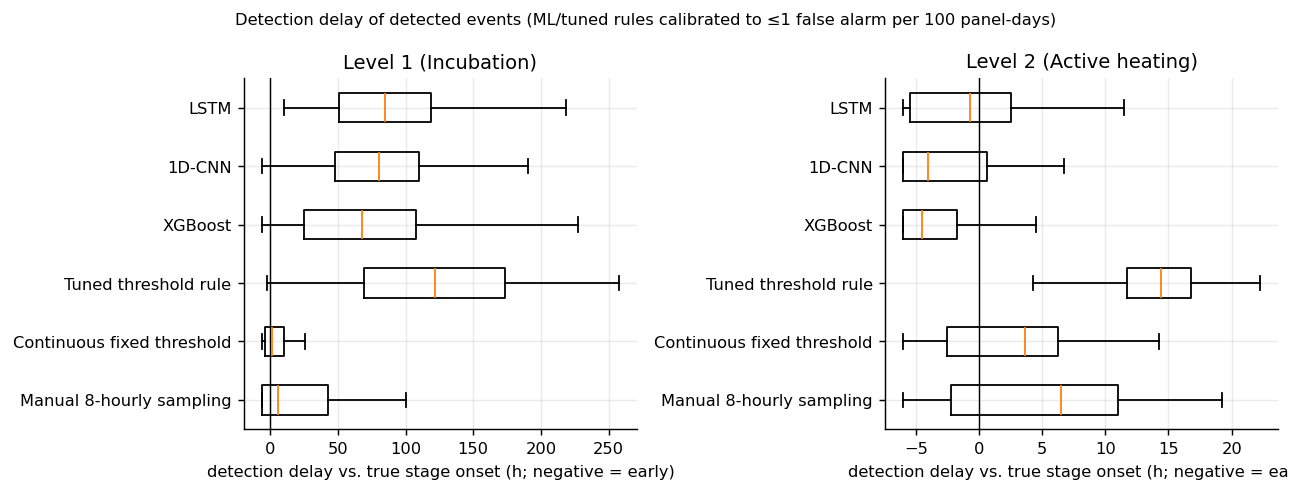

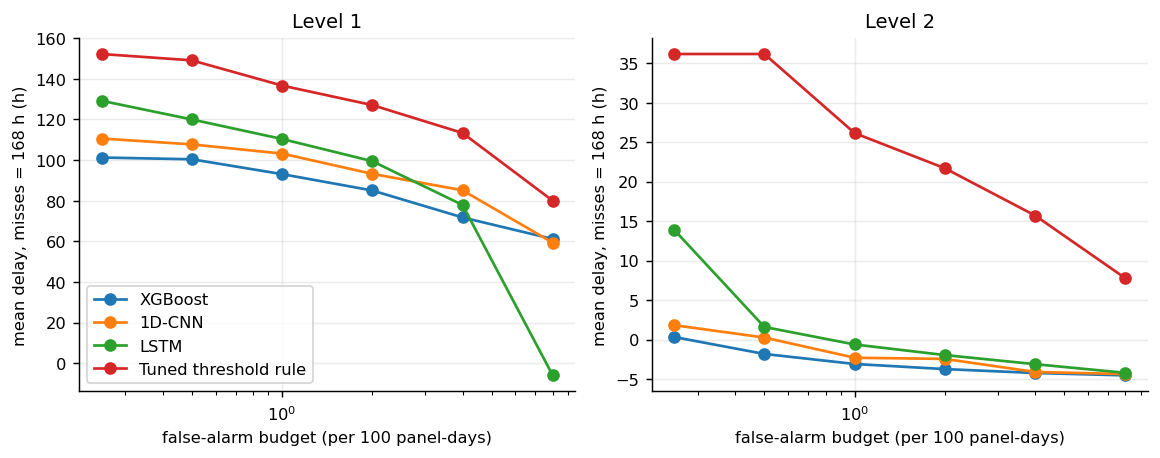

In [9]:
display(Image("../reports/figures/fig05_detection_delay.png")); display(Image("../reports/figures/fig06_operating_curve.png"))

**Paired lead time** — hours by which XGBoost's alarm precedes each baseline's alarm on the *same* events:

In [10]:
pl = R["paired_lead"]["xgb"]; rows = []
for b, per in pl.items():
    for k, r in per.items(): rows.append({"vs baseline": b, "level": k, "median lead (h)": r["median_lead_h"], "paired events": r["n_paired"],
                                          "events only ML caught": r["model_only_detected"], "events only baseline caught": r["baseline_only_detected"]})
pd.DataFrame(rows).round(1)

,vs baseline,level,median lead (h),paired events,events only ML caught,events only baseline caught
0,Manual 8-hourly sampling,1,-27.5,57,3,13
1,Manual 8-hourly sampling,2,8.8,37,2,0
2,Manual 8-hourly sampling,3,-3.8,28,0,0
3,Continuous fixed threshold,1,-62.1,60,0,15
4,Continuous fixed threshold,2,6.8,38,1,0
5,Continuous fixed threshold,3,-5.2,28,0,0
6,Tuned threshold rule,1,46.0,38,22,1
7,Tuned threshold rule,2,17.6,36,3,0
8,Tuned threshold rule,3,-5.2,28,0,0


## 6. Explainability (TreeSHAP)

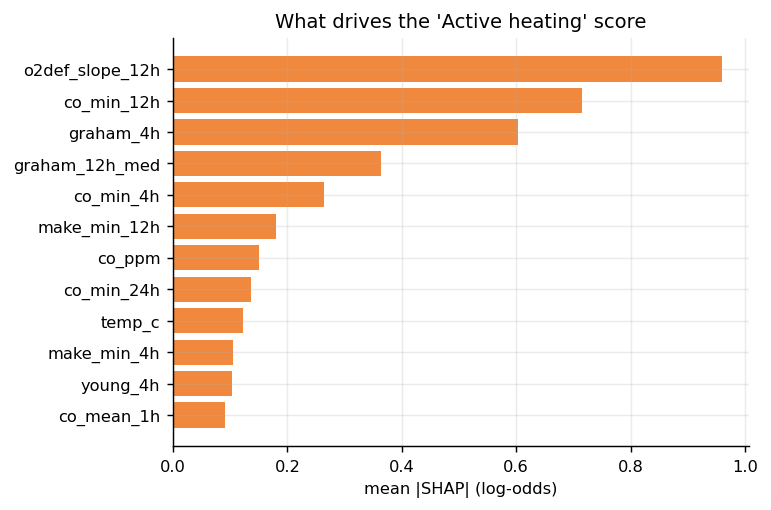

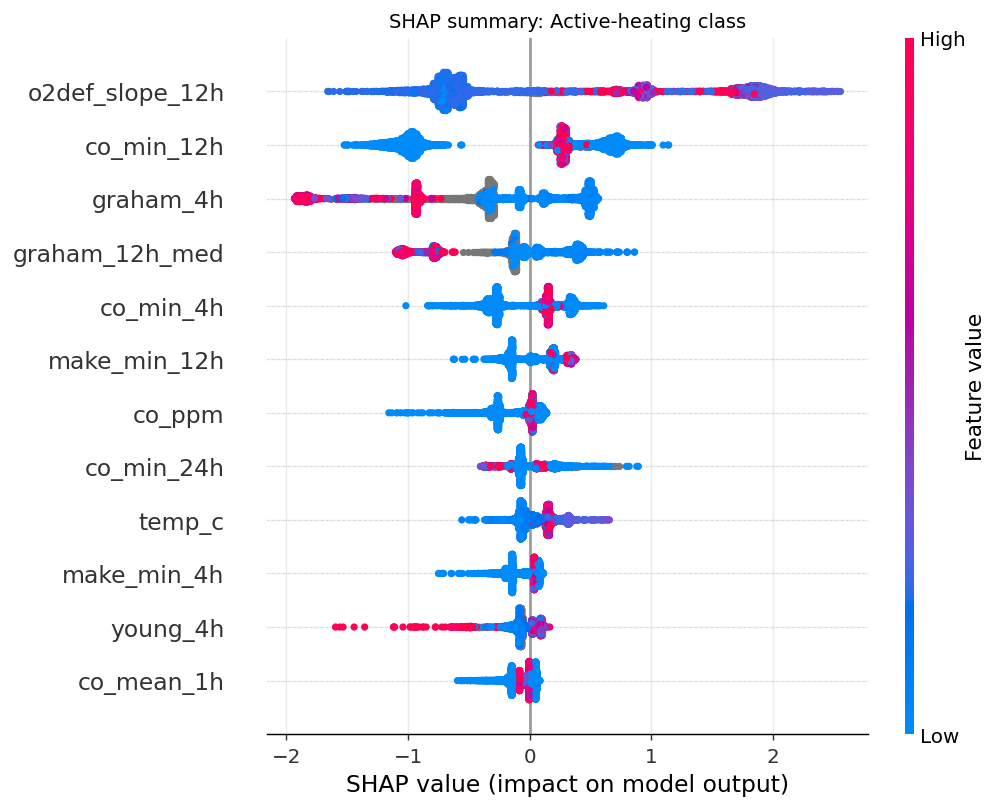

In [11]:
display(Image("../reports/figures/fig07_shap_importance.png"))
import os
if os.path.exists("../reports/figures/fig07b_shap_beeswarm.png"): display(Image("../reports/figures/fig07b_shap_beeswarm.png"))

In [12]:
from ews.models.tabular import XGBStageModel
from ews.serving.describe import describe
m = XGBStageModel.load("../artifacts/xgb_stage.json")
i = int(np.where((T.st == 2) & T.valid)[0][50])                       # an Active-heating row
contrib = m.contributions(T.F.iloc[[i]])[0][2, :-1]
top = np.argsort(-np.abs(contrib))[:6]
pd.DataFrame({"feature": [describe(m.feature_names[j]) for j in top], "value": T.F.iloc[i, top].values.round(2), "SHAP (log-odds)": contrib[top].round(2)})

,feature,value,SHAP (log-odds)
0,oxygen-deficiency trend,0.010000,2.00
1,co min 12h,13.000000,0.59
2,Graham's ratio (4-h),1.130000,0.53
3,Graham's ratio (12-h median),0.810000,0.33
4,co min 4h,35.000000,0.33
5,make min 12h,33.099998,0.19


## 7. Ablation: which parts of the feature set matter?

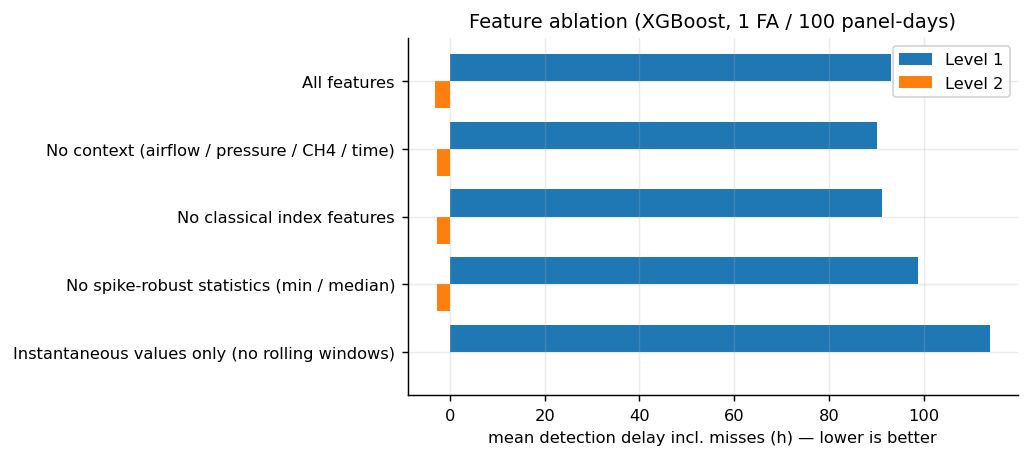

In [13]:
display(Image("../reports/figures/fig08_ablation.png"))

## 8. Stress tests and edge cases
We re-simulate with more sensor noise, weaker heating CO, and heavy telemetry dropout **without retraining**, and run named scenarios (fast runaway, slow incubation, dropout during heating, ventilation shock, blasting storm, self-quenching).

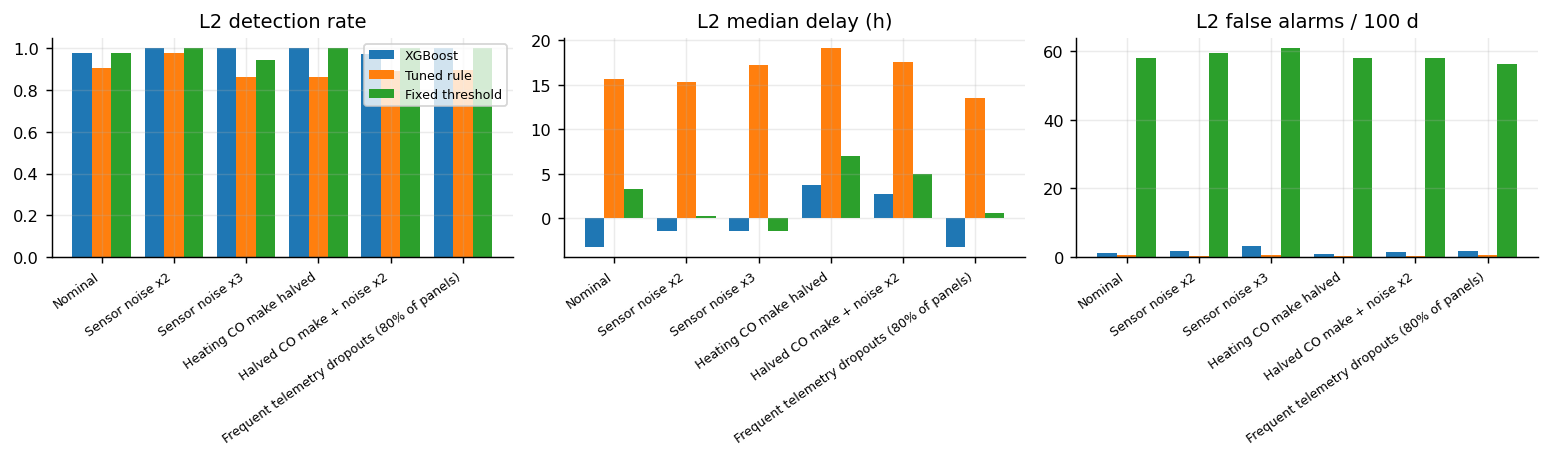

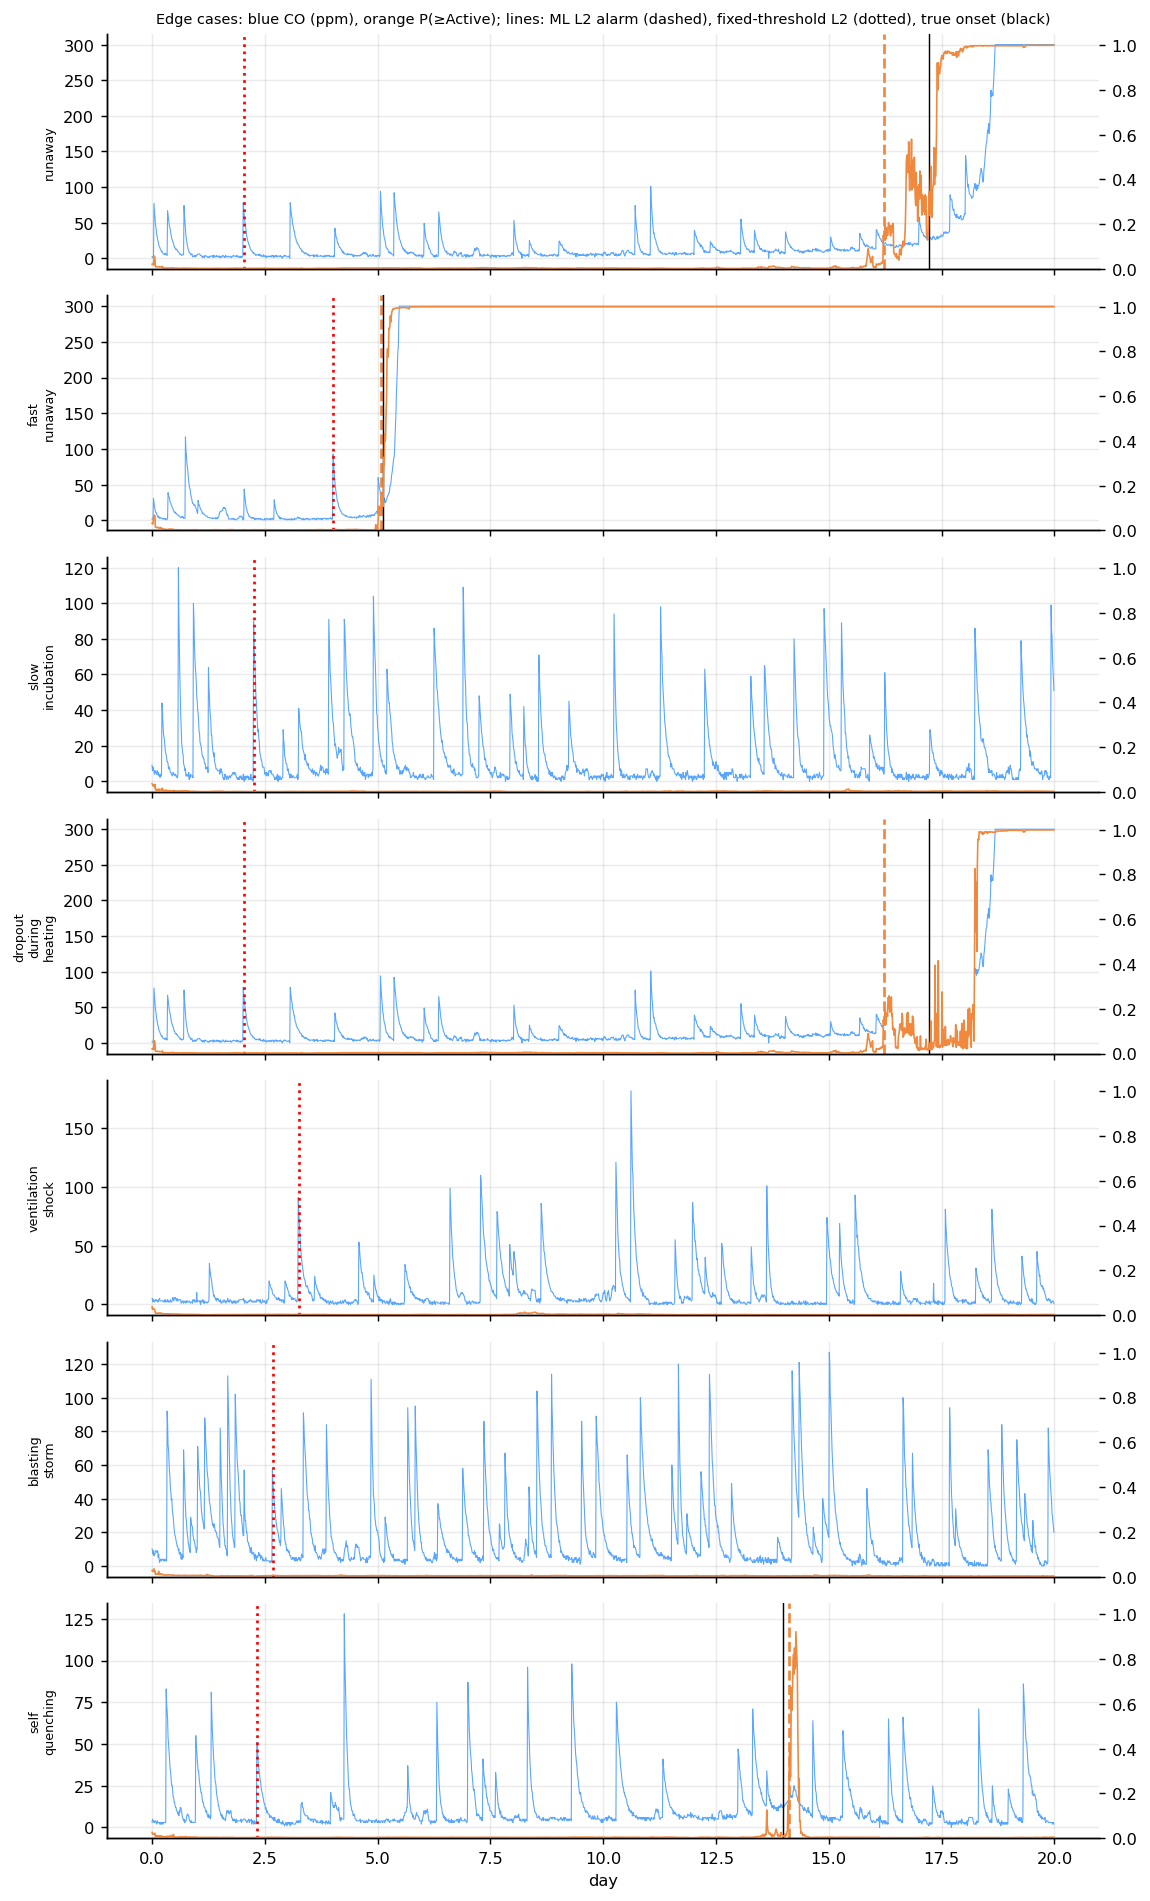

,L2 onset (d),ML alarm (d),fixed-threshold alarm (d),ML false alarms (L1-3),fixed false alarms (L1-3)
runaway,17.229167,16.218750,2.031250,1.0,15.0
fast_runaway,5.125000,5.083333,4.020833,0.0,3.0
slow_incubation,NaN,NaN,2.260417,0.0,25.0
dropout_during_heating,17.229167,16.218750,2.031250,2.0,15.0
ventilation_shock,NaN,NaN,3.250000,1.0,30.0
blasting_storm,NaN,NaN,2.677083,2.0,43.0
self_quenching,13.989583,14.125000,2.333333,0.0,26.0


In [14]:
display(Image("../reports/figures/fig09_sensitivity.png")); display(Image("../reports/figures/fig10_scenarios.png"))
pd.DataFrame({k: {"L2 onset (d)": v["L2"]["stage_onset_day"], "ML alarm (d)": v["L2"]["model_first_alarm_day"], "fixed-threshold alarm (d)": v["L2"]["baseline_first_alarm_day"],
                  "ML false alarms (L1-3)": sum(v[f"L{j}"]["model_false_alarms"] for j in (1,2,3)),
                  "fixed false alarms (L1-3)": sum(v[f"L{j}"]["baseline_false_alarms"] for j in (1,2,3))} for k, v in R["scenarios"].items()}).T

## 9. Conclusions and limitations
See the report for the narrative. Key caveats: simulated data; Level-1 (incubation) detection is slow; performance on real mines is unknown until the simulator is calibrated or the model is validated on real gas logs.